# City Complaint Prediction 

**Objective:** Build a regression model that predicts the number of 311 service complaints filed per ZIP code on any given day, using weather conditions, infrastructure history, and calendar features as predictors.

### Why this problem is worth solving
Cities receive thousands of complaints daily. If a model can forecast which ZIP codes will spike in complaints tomorrow, resources like inspection crews and call centre staff can be pre-positioned rather than reacting after the fact. This turns a reactive system into a proactive one.

### Why regression and not classification?
The output — complaint count — is a continuous number (0, 3, 47, 200…). Classification only works when the output is a discrete category (yes/no, low/medium/high). Predicting an actual count gives city planners far more actionable information.

### Pipeline Overview
| Stage | Purpose |
|---|---|
| 1. Load & Clean | Understand data shape, fix missing values |
| 2. EDA | Visualise distributions, seasonality, correlations |
| 3. Feature Engineering | Create new, more informative columns |
| 4. Feature Selection | Remove redundant columns that add noise |
| 5. Log Transform | Stabilise the skewed target variable |
| 6. Train/Test Split | Use Time-Series Split to avoid future data leakage |
| 7. Iterative Modelling | Try LightGBM, lag features, rolling averages — measure impact of each change |
| 8. Hyperparameter Tuning | Squeeze out remaining performance with RandomizedSearchCV |
| 9. Final Comparison | Benchmark the tuned Random Forest against linear baselines |


## Step 0 — Installing Libraries and Setting Global Configuration

Before any analysis begins, we install and import every library the pipeline needs. This is done upfront so that any missing dependency causes an immediate, obvious error rather than a silent failure 200 lines in.

**Key library choices and why:**
- **pandas / numpy** — the standard tools for tabular data manipulation and numerical computation in Python
- **scikit-learn** — provides cross-validation, preprocessing, linear models, ensemble models, and evaluation metrics under a unified API
- **LightGBM** — a gradient-boosted tree library from Microsoft, known for training speed and accuracy on tabular data; often outperforms standard sklearn ensembles
- **XGBoost** — another gradient-boosted tree library (by Chen & Guestrin); similar to LightGBM but uses a different regularisation strategy
- **holidays** — a small library that maps dates to US public holidays; essential for creating the `is_holiday` feature
- **matplotlib / seaborn** — for static plots; seaborn adds statistical chart types (boxplots, heatmaps) on top of matplotlib

The `plt.rcParams.update(...)` block enforces a consistent visual style across all 15+ plots in this notebook — white backgrounds, subtle grids, and uniform font sizes — so every chart looks professional without repeating styling code each time.

`SEED = 42` and `np.random.seed(SEED)` guarantee that any random operation (shuffling, sampling, tree splitting) produces the same result on every run, making the experiment fully reproducible.


In [1]:
!pip install optuna lightgbm xgboost holidays scikit-learn --quiet

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.pipeline import Pipeline
import lightgbm as lgb
import xgboost as xgb
import holidays

# Make all plots look clean and consistent
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#f9f9f9',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold'
})
SEED = 42
np.random.seed(SEED)
print("All libraries loaded!")

All libraries loaded!


## Step 1 — Loading the Data and Initial Inspection

The dataset is a pre-aggregated table where each row represents one ZIP code on one date, with its complaint count and associated features (weather readings, infrastructure metrics, etc.).

**Why we immediately call `.info()` and compute null percentages:**  
Raw data is almost never clean. `.info()` reveals column data types — a date stored as `object` instead of `datetime64` would break time-series operations. Null percentages, expressed as a fraction of total rows rather than raw counts, are far more interpretable: "3% missing" means something very different in a 100-row dataset vs. a 100,000-row dataset.

**Why we visualise missing values as a bar chart rather than just printing numbers:**  
A chart makes the severity of missingness immediately obvious. A column that is 80% missing should probably be dropped; a column that is 0.5% missing can be imputed. Seeing them side by side on one chart allows that decision to be made at a glance.

**Why we drop rows where `borough` is missing (not impute):**  
Borough is a categorical grouping variable, not a numerical measurement. There is no meaningful "average borough" to fill in. If the borough is unknown, the row cannot be correctly attributed to any geographic group, making it unusable for neighbourhood-level analysis.

**Why we sort by date after loading:**  
All downstream operations — lag features, rolling averages, Time-Series Split — require the data to be in strict chronological order. Sorting once here prevents subtle ordering bugs later.


In [3]:
df = pd.read_csv("modeling_table_final.csv")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date range: {df['date'].min()}  to  {df['date'].max()}")
df.info()

Shape: 162,769 rows x 30 columns
Date range: 2020-01-01  to  2024-12-31
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162769 entries, 0 to 162768
Data columns (total 30 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   incident_zip          162769 non-null  int64  
 1   date                  162769 non-null  object 
 2   borough               160951 non-null  object 
 3   request_count         162769 non-null  int64  
 4   complaint_type_count  162769 non-null  int64  
 5   year                  162769 non-null  int64  
 6   month                 162769 non-null  int64  
 7   day_of_week           162769 non-null  int64  
 8   day_of_year           162769 non-null  int64  
 9   season                162769 non-null  int64  
 10  is_weekend            162769 non-null  int64  
 11  is_holiday            162769 non-null  int64  
 12  tmax                  162769 non-null  float64
 13  tmin                  162769 non

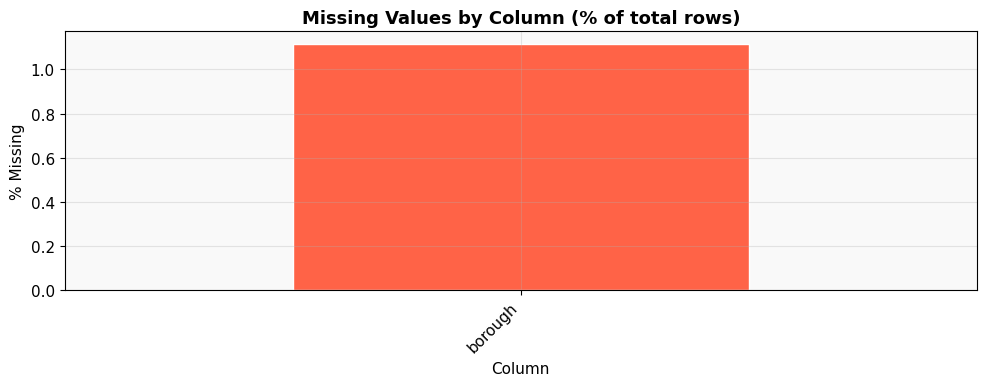

borough    1.11692
dtype: float64


In [4]:
# Check missing values — expressed as percentage so it's more meaningful
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

if len(null_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    null_pct.plot(kind='bar', color='tomato', ax=ax, edgecolor='white')
    ax.set_title("Missing Values by Column (% of total rows)")
    ax.set_ylabel("% Missing")
    ax.set_xlabel("Column")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    print(null_pct)
else:
    print("No missing values found!")

In [5]:
# Drop rows where borough is missing — borough is a category, we can't guess it
before = len(df)
df = df.dropna(subset=['borough'])
print(f"Dropped {before - len(df)} rows with missing borough. Remaining: {len(df):,} rows")

# Convert date column to proper datetime format
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
print("Data sorted by date. Ready for time-series work.")

Dropped 1818 rows with missing borough. Remaining: 160,951 rows
Data sorted by date. Ready for time-series work.


## Step 2 — Exploratory Data Analysis (EDA)

EDA is the process of understanding data before modelling. It answers questions like: Is the target variable normally distributed or heavily skewed? Do weather conditions correlate with complaint volume? Are there weekly or seasonal cycles?

**Why EDA matters before modelling:**  
Models are not magic. If you feed a linear model a highly skewed target, it will perform poorly — not because the algorithm is wrong, but because the data violated the algorithm's assumptions. EDA exposes these issues early so that the right preprocessing choices can be made.

Every chart in this section is designed to answer one specific question about the data. The findings directly inform decisions made in Steps 3–5.


### 2.1 — Understanding the Target Variable: Complaint Count Distribution

Three complementary views of the same variable are plotted because each reveals something different:

**Plot 1 — Raw histogram with log-scaled y-axis:**  
The y-axis (frequency) is log-scaled, not the data itself. This is used because the distribution has a very long right tail — most ZIP codes have low counts on most days, but a few have extremely high counts. On a linear y-axis, the bars for rare high-count events would be invisible. The log scale compresses the y-axis so rare events become visible alongside common ones.

**Plot 2 — Log-transformed histogram with KDE overlay:**  
Here we apply `log(x + 1)` to the complaint counts themselves (the x-axis). This is the same transformation we later apply to the target variable before training. The resulting distribution is closer to a bell curve (Gaussian), which most regression algorithms implicitly assume. The KDE (Kernel Density Estimate) curve is a smoothed version of the histogram — it shows the overall shape without the noise of individual bins.

**Plot 3 — Time series with 7-day rolling average:**  
The raw daily series is extremely noisy — individual days spike up and down. The 7-day rolling average smooths over this noise and reveals the underlying trend: are complaints rising or falling over months? This plot also reveals seasonality (e.g., summer spikes) that a model needs to learn.


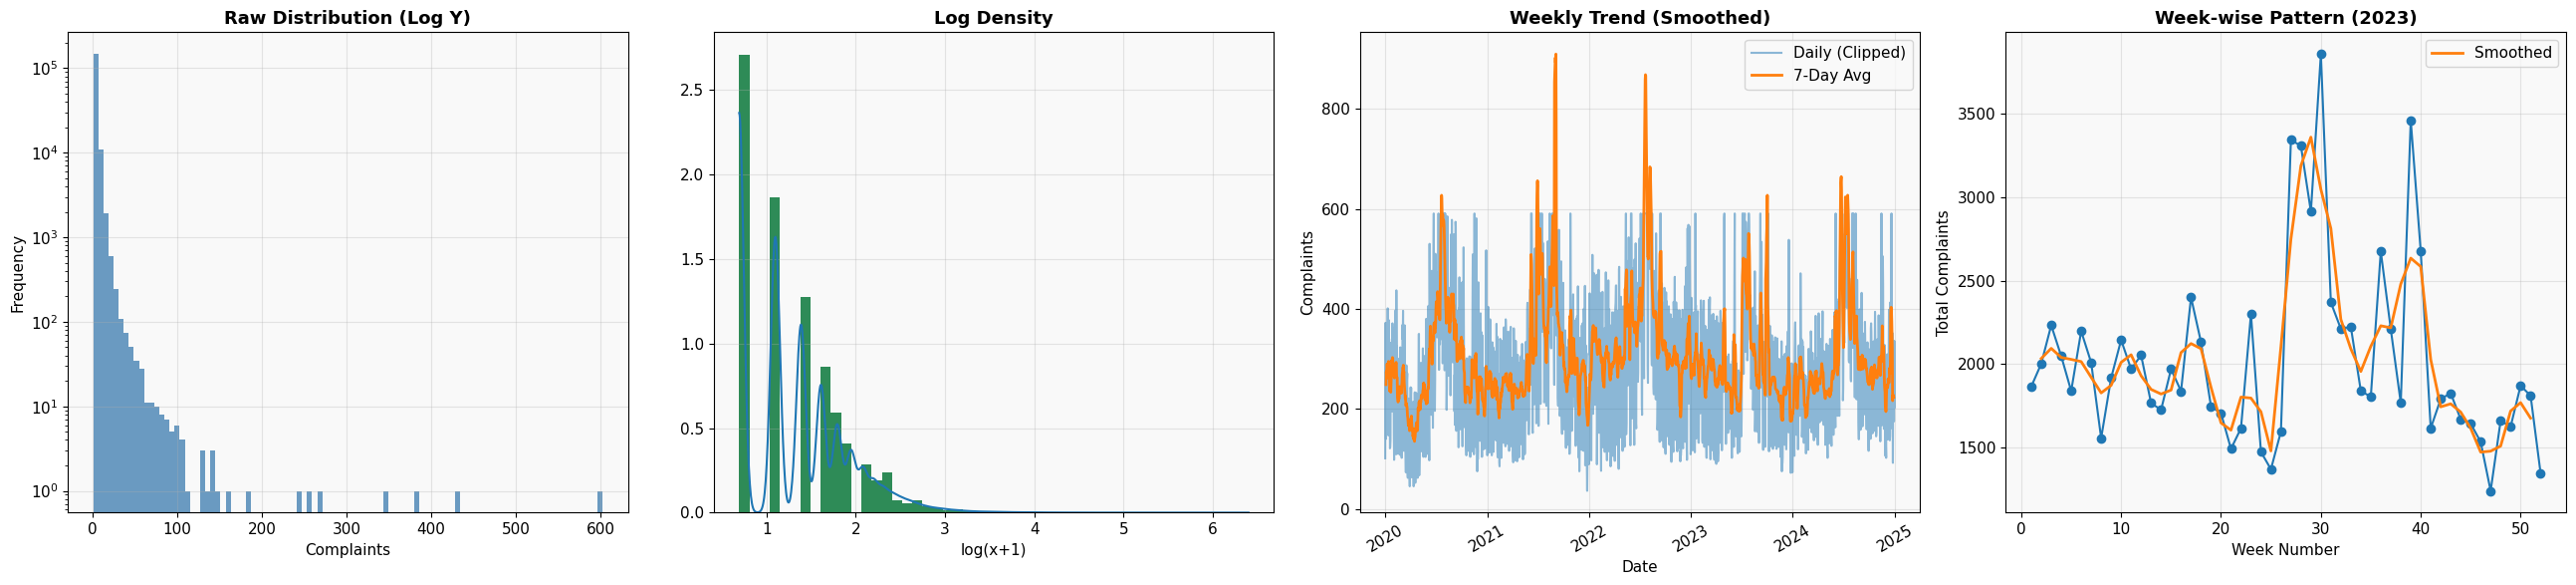

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

# Ensure date is datetime
df['date'] = pd.to_datetime(df['date'])

fig, axes = plt.subplots(1, 4, figsize=(26, 6))

# 1. Raw Distribution
axes[0].hist(df['request_count'], bins=100, color='steelblue', alpha=0.8)
axes[0].set_yscale('log')
axes[0].set_title("Raw Distribution (Log Y)")
axes[0].set_xlabel("Complaints")
axes[0].set_ylabel("Frequency")

# 2. Log Transformed
log_data = np.log1p(df['request_count'])
axes[1].hist(log_data, bins=50, density=True, color='seagreen')

x_range = np.linspace(log_data.min(), log_data.max(), 1000)
kde = gaussian_kde(log_data)
axes[1].plot(x_range, kde(x_range))

axes[1].set_title("Log Density")
axes[1].set_xlabel("log(x+1)")

# 3. Time Series (Improved)
daily = df.groupby('date')['request_count'].sum()
weekly_rolling = daily.rolling(window=7, center=True).mean()

upper_limit = daily.quantile(0.95)
daily_clipped = daily.clip(upper=upper_limit)

axes[2].plot(daily.index, daily_clipped, alpha=0.5, label='Daily (Clipped)')
axes[2].plot(daily.index, weekly_rolling, linewidth=2, label='7-Day Avg')

axes[2].set_title("Weekly Trend (Smoothed)")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Complaints")
axes[2].legend()

# 4. Week-wise Pattern for a Specific Year
year = 2023  # change this if needed

df_year = df[df['date'].dt.year == year].copy()

# ISO week number
df_year['week'] = df_year['date'].dt.isocalendar().week

weekly_pattern = df_year.groupby('week')['request_count'].sum()

axes[3].plot(weekly_pattern.index, weekly_pattern.values, marker='o')
axes[3].set_title(f"Week-wise Pattern ({year})")
axes[3].set_xlabel("Week Number")
axes[3].set_ylabel("Total Complaints")

# Optional: smooth to see pattern clearly
weekly_smooth = weekly_pattern.rolling(3, center=True).mean()
axes[3].plot(weekly_pattern.index, weekly_smooth, linewidth=2, label='Smoothed')
axes[3].legend()

# Final layout
plt.setp(axes[2].get_xticklabels(), rotation=30)
plt.tight_layout()
plt.show()

### Observations from the Distribution Plots

**On the log y-axis (Plot 1):** The scale change reveals that high complaint counts are rare but non-trivial — they cannot simply be ignored as outliers. This justifies keeping the full range rather than capping or removing extreme values.

**On the log-transformed x-axis (Plot 2):** The distribution becomes approximately symmetric and bell-shaped after the log transformation. This is important because linear models assume normally distributed errors, and tree-based models also benefit from a less skewed target because it reduces the range of values the model needs to predict — making splits more informative.

**On the weekly cycles (Plot 3):** The rolling average reveals that complaint volume is not random — there are recurring patterns. The model must be given access to time-based features (day of week, month, lags) so it can learn these patterns, rather than treating each day as independent.


### 2.2 — Weather Effect: Does Rainfall Increase Complaints?

**Why we bin continuous rainfall into categories:**  
Raw precipitation values range from 0.00 to several inches. Binning into four meaningful categories — No Rain, Light, Moderate, Heavy — makes the relationship interpretable. A boxplot showing average complaint count across these four bins is far more readable than a scatter plot of raw millimetres vs. complaint count.

**Why we use `showfliers=False` in the boxplot:**  
Outlier dots in boxplots often dominate the visual space and obscure the central tendencies we actually care about. Since the distribution is heavily right-skewed (a few ZIP codes always have high counts regardless of rain), hiding individual outliers and focusing on the interquartile range (the box) gives a cleaner picture of how the *typical* ZIP code responds to rainfall.

**What this tells us for modelling:** If average complaints increase monotonically with rain severity, then `prcp` (precipitation) is a useful predictive feature and should be retained. This EDA chart is the evidence base for that decision.


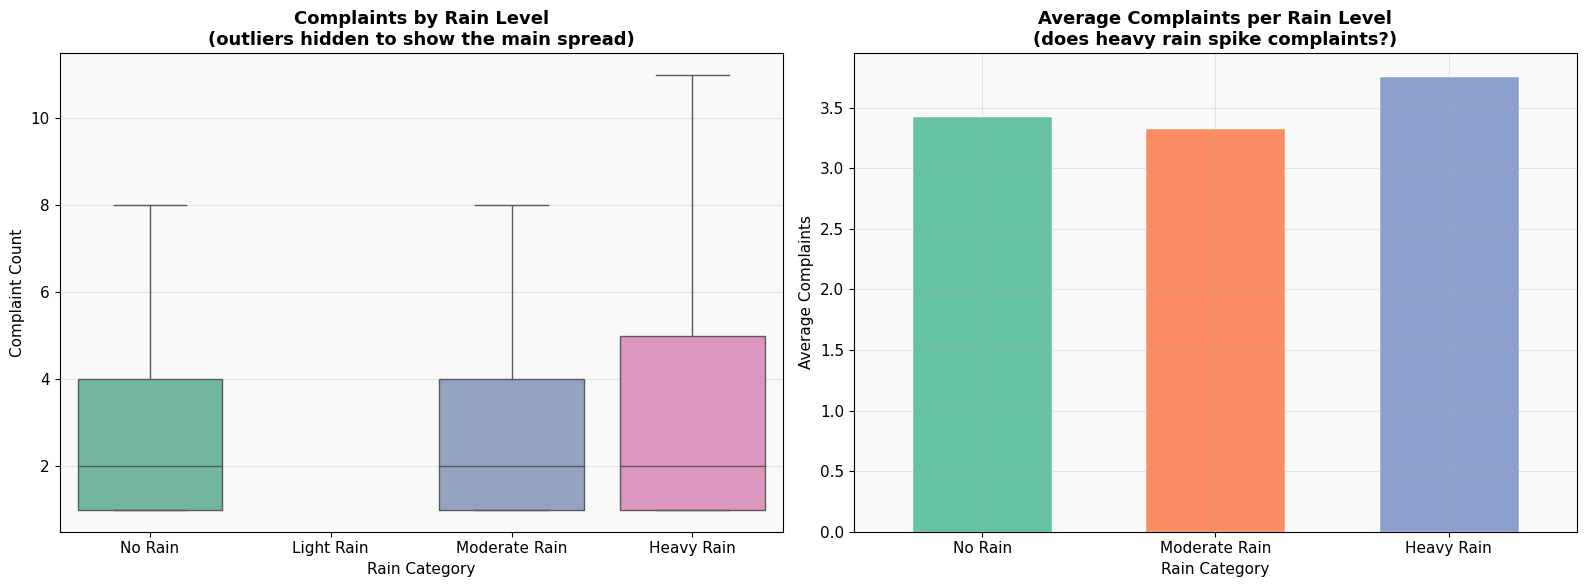

In [7]:
max_prcp = df['prcp'].max()
bins   = [-0.01, 0.01, 0.25, 1.0, max_prcp + 0.1]
labels = ['No Rain', 'Light Rain', 'Moderate Rain', 'Heavy Rain']
df['prcp_cat'] = pd.cut(df['prcp'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot by rain category
sns.boxplot(x='prcp_cat', y='request_count', data=df,
            showfliers=False, palette='Set2', ax=axes[0])
axes[0].set_title("Complaints by Rain Level\n(outliers hidden to show the main spread)")
axes[0].set_xlabel("Rain Category")
axes[0].set_ylabel("Complaint Count")

# Average complaints per rain category
avg_by_rain = df.groupby('prcp_cat', observed=True)['request_count'].mean()
avg_by_rain.plot(kind='bar', color=['#66c2a5','#fc8d62','#8da0cb','#e78ac3'],
                 ax=axes[1], edgecolor='white', width=0.6)
axes[1].set_title("Average Complaints per Rain Level\n(does heavy rain spike complaints?)")
axes[1].set_xlabel("Rain Category")
axes[1].set_ylabel("Average Complaints")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("plot_02_weather_effect.png", dpi=150, bbox_inches='tight')
plt.show()

### 2.3 — Temporal Patterns: Day of Week and Month Effects

**Why we plot day-of-week and month separately:**  
These are two different types of periodicity. Day-of-week captures the weekly cycle (7-day period); month captures the annual cycle (12-month period). A model needs features for both. Seeing the bar heights differ across days confirms that `day_of_week` contains genuine predictive signal and is not just noise.

**Why complaints are lower on weekends:**  
Weekend effects are a well-known phenomenon in 311 complaint data. Several mechanisms contribute: (1) some complaint types (noise, parking, construction) are more common during business hours; (2) residents may be less likely to file formal complaints on weekends; (3) city offices that process and log complaints may run with reduced staffing, causing lower recorded counts even if true incidents are similar.

**Why month matters:**  
Seasonal infrastructure stress explains monthly patterns. Water main breaks increase in winter due to freeze-thaw cycles; heat-related complaints spike in summer; construction and noise complaints peak in spring and summer when outdoor work is active.


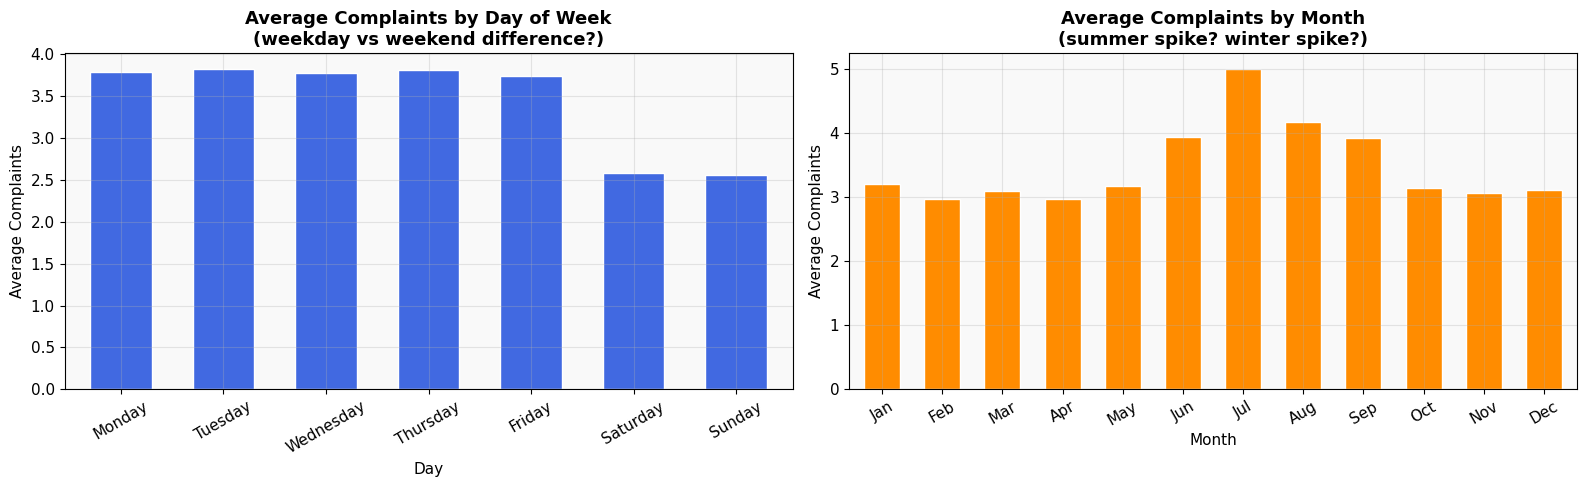

In [8]:
df['day_of_week'] = df['date'].dt.dayofweek
day_names = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Average complaints by day
dow_avg = df.groupby('day_of_week')['request_count'].mean()
dow_avg.index = [day_names[i] for i in dow_avg.index]
dow_avg.plot(kind='bar', color='royalblue', ax=axes[0], edgecolor='white', width=0.6)
axes[0].set_title("Average Complaints by Day of Week\n(weekday vs weekend difference?)")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Average Complaints")
plt.sca(axes[0]); plt.xticks(rotation=30)

# Monthly pattern
df['month'] = df['date'].dt.month
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
month_avg = df.groupby('month')['request_count'].mean()
month_avg.index = [month_names[i-1] for i in month_avg.index]
month_avg.plot(kind='bar', color='darkorange', ax=axes[1], edgecolor='white', width=0.6)
axes[1].set_title("Average Complaints by Month\n(summer spike? winter spike?)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Average Complaints")
plt.sca(axes[1]); plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("plot_03_time_patterns.png", dpi=150, bbox_inches='tight')
plt.show()

### Observations: Weekend Dip and Rain Spike

**Weekend dip:** The data confirms a consistent drop in complaint volume on Saturday and Sunday. This is not an error — it reflects real behavioural and operational patterns. For modelling, we encode `day_of_week` as a feature (and later use cyclical encoding) so the model can learn this weekly rhythm.

**Rain spike:** Heavy rainfall days show systematically higher complaint volumes. The most plausible explanation is infrastructure stress: heavy rain overloads drainage, causes road flooding, triggers water main pressure changes, and exposes structural weaknesses. Each of these generates a complaint category. Including `prcp` (precipitation) as a feature is therefore justified by this evidence.

These two findings together suggest that a model without temporal and weather features would leave significant predictive power on the table.


### 2.4 — Borough-Level Analysis: Geographic Heterogeneity

**Why we plot borough-level averages:**  
The city is not homogeneous. Different boroughs have different population densities, infrastructure ages, and reporting cultures. If complaint rates vary systematically by borough, then geography is a predictive signal. A model that ignores geography would conflate a high-complaint Manhattan ZIP code with a low-complaint Staten Island ZIP code.

**Why we use both a bar chart (average) and a boxplot (spread):**  
The bar chart shows which borough has the highest *average* complaint rate — useful for understanding the typical level. The boxplot shows the *spread* within each borough — a wide box means high day-to-day variability; a narrow box means the complaint rate is stable. Both pieces of information are relevant: a high-variability borough is harder to predict accurately, which affects how we interpret model errors.


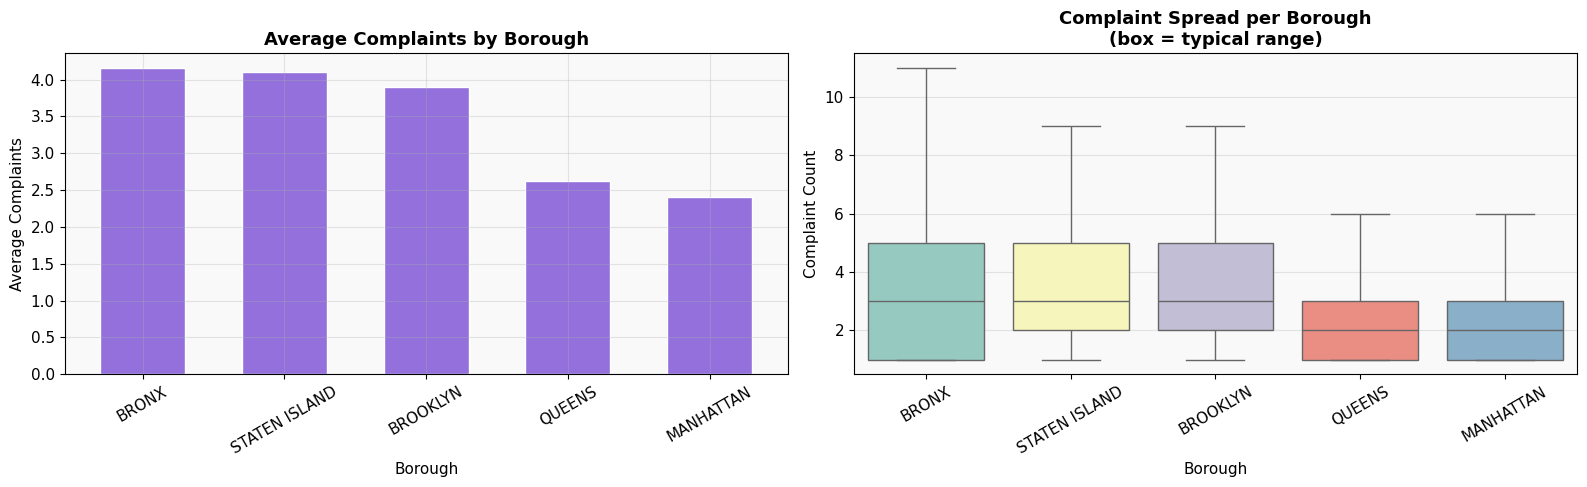

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Average complaints per borough
boro_avg = df.groupby('borough')['request_count'].mean().sort_values(ascending=False)
boro_avg.plot(kind='bar', color='mediumpurple', ax=axes[0], edgecolor='white', width=0.6)
axes[0].set_title("Average Complaints by Borough")
axes[0].set_xlabel("Borough")
axes[0].set_ylabel("Average Complaints")
plt.sca(axes[0]); plt.xticks(rotation=30)

# Boxplot per borough
borough_order = boro_avg.index.tolist()
sns.boxplot(x='borough', y='request_count', data=df,
            order=borough_order, showfliers=False,
            palette='Set3', ax=axes[1])
axes[1].set_title("Complaint Spread per Borough\n(box = typical range)")
axes[1].set_xlabel("Borough")
axes[1].set_ylabel("Complaint Count")
plt.sca(axes[1]); plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("plot_04_borough.png", dpi=150, bbox_inches='tight')
plt.show()

### 2.5 — Lag Relationship: Does Yesterday Predict Today?

**What a lag feature is:**  
A lag feature is simply the value of the target variable from a previous time step. `lag_1d` = yesterday's complaint count for the same ZIP code. `lag_7d` = the count from the same day last week. These are among the most powerful features in any time-series model because they capture momentum and recurring weekly patterns.

**Why we use a scatter plot with a trend line:**  
If yesterday's count is a strong predictor of today's count, the scatter plot will show points clustering tightly around the trend line, and the slope will be steep (close to 1). If the relationship is weak, points will be scattered widely and the slope will be flat. The correlation coefficient `r` gives a single number summary of this relationship.

**Why the correlation is moderate rather than very high:**  
Complaint counts depend on many factors — weather events, specific incidents, random variation. A single ZIP code's behaviour is noisy enough that yesterday's count alone is not a perfect predictor. This motivates using lags *in combination* with weather and infrastructure features rather than relying on them alone.


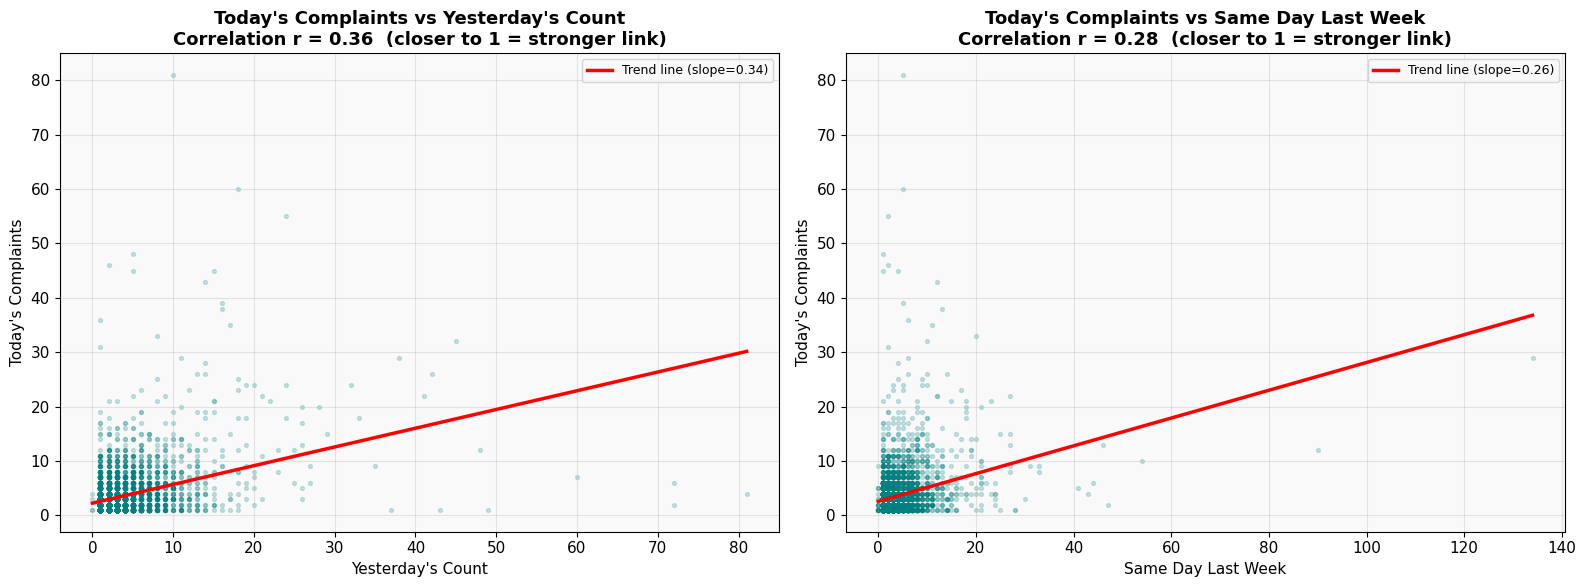

Interpretation: if the slope is steep and points cluster near the red line, the lag feature is VERY useful.But if the slope is flat and points are widely scattered, the lag feature may not add much predictive power.here the dots are wide spread and the slope is not very steep, suggesting that while there is some relationship, it's not strong enough to rely on heavily for predictions.


In [12]:
df_sample = df[['lag_request_1d','lag_request_7d','request_count']].dropna().sample(5000, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, col, title_extra in zip(axes,
                                ['lag_request_1d','lag_request_7d'],
                                ["Yesterday's Count","Same Day Last Week"]):
    ax.scatter(df_sample[col], df_sample['request_count'],
               alpha=0.2, color='teal', s=8)
    # Draw a simple trend line
    m, b = np.polyfit(df_sample[col].fillna(0), df_sample['request_count'], 1)
    x_line = np.linspace(df_sample[col].min(), df_sample[col].max(), 200)
    ax.plot(x_line, m*x_line + b, color='red', linewidth=2.5, label=f'Trend line (slope={m:.2f})')
    r = df_sample[[col,'request_count']].dropna().corr().iloc[0,1]
    ax.set_title(f"Today's Complaints vs {title_extra}\nCorrelation r = {r:.2f}  (closer to 1 = stronger link)")
    ax.set_xlabel(title_extra)
    ax.set_ylabel("Today's Complaints")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("plot_05_lag_relationship.png", dpi=150, bbox_inches='tight')
plt.show()
print("Interpretation: if the slope is steep and points cluster near the red line, the lag feature is VERY useful.But if the slope is flat and points are widely scattered, the lag feature may not add much predictive power.here the dots are wide spread and the slope is not very steep, suggesting that while there is some relationship, it's not strong enough to rely on heavily for predictions.")

### 2.6 — Correlation Heatmap: Identifying Redundant Features

**Why we compute a correlation matrix:**  
When two features are highly correlated (r > 0.8 or r < -0.8), they carry nearly identical information. Including both in a model creates multicollinearity, which makes linear model coefficients unstable and wastes capacity in tree-based models by splitting on the same signal twice.

**Why we use `cmap='RdBu_r'` with `center=0`:**  
This colour scheme maps negative correlations to red, zero to white, and positive correlations to blue. Setting `center=0` ensures white always represents zero correlation — making it immediately visually obvious which pairs of features move together (blue) vs. in opposite directions (red) vs. independently (white).

**What we look for:** Pairs like `tmax`/`tmin` (maximum and minimum temperature) will show near-perfect correlation. Keeping both adds no new information — this is the evidence that motivates dropping one of them in Step 4 and replacing both with `temp_range`.


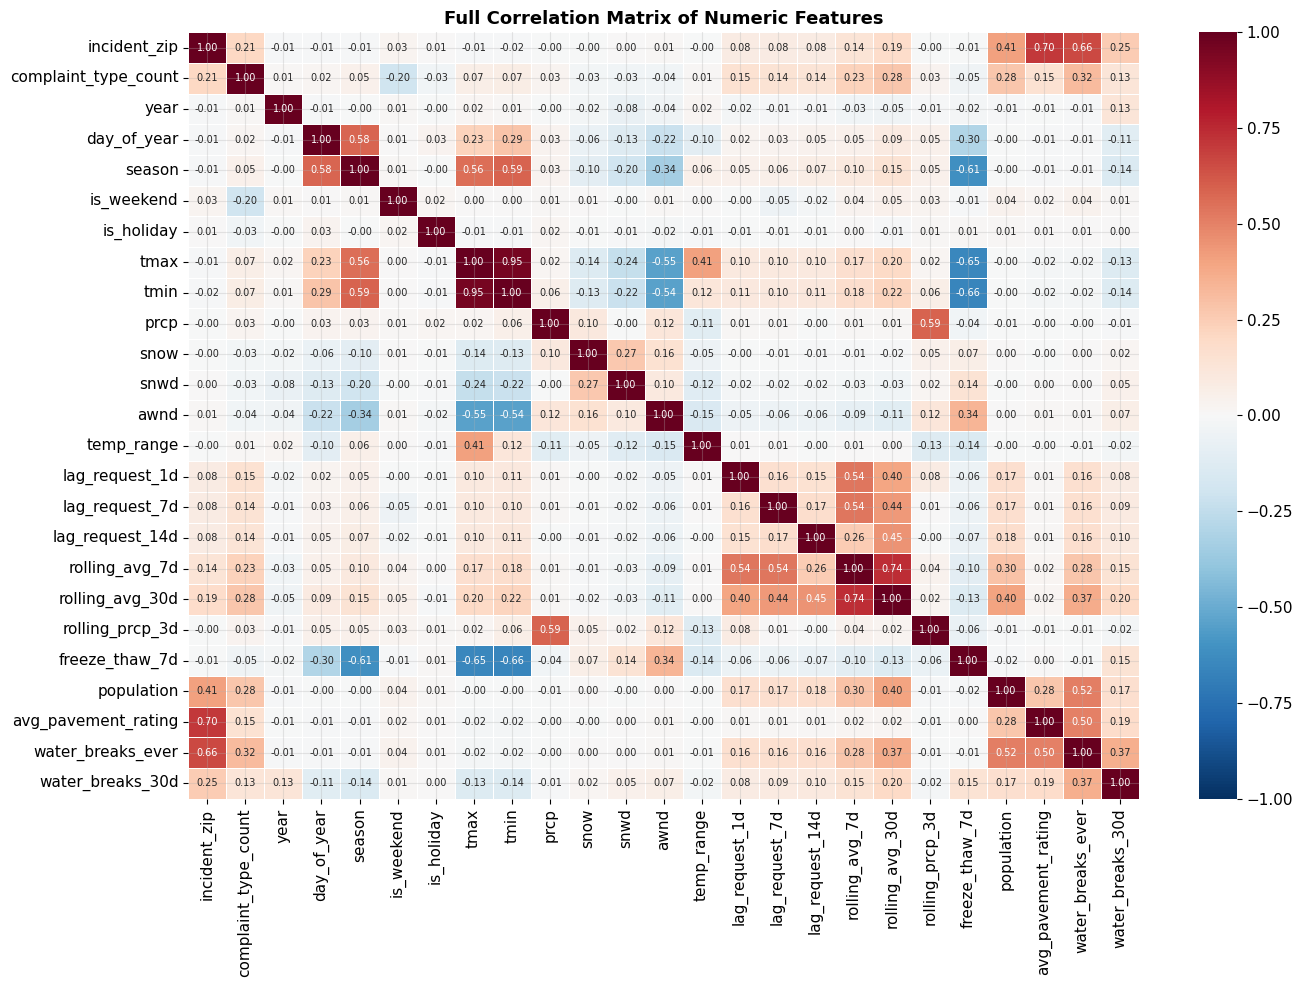

In [13]:
# Use your existing logic to get numeric columns
numeric_df = df.select_dtypes(include=['int64','float64']).drop(columns=['request_count'], errors='ignore')
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(14, 10))

# REMOVED: mask = np.triu(...)
# ADDED: center=0 to make the scale intuitive

sns.heatmap(corr, 
            annot=True, 
            cmap='RdBu_r',   # Red-Blue palette is clearer for full squares
            vmin=-1, 
            vmax=1,
            center=0,        # Forces 0 to be white
            fmt='.2f', 
            linewidths=0.4, 
            ax=ax, 
            annot_kws={'size': 7})

ax.set_title("Full Correlation Matrix of Numeric Features")
plt.tight_layout()

# Save and show
plt.savefig("plot_06_correlation_heatmap_full.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 3 — Feature Engineering: Creating More Informative Inputs

Feature engineering is the process of transforming raw columns into representations that better capture the underlying patterns the model needs to learn. Raw data is often not in the optimal form for a machine learning algorithm.

**Cyclical encoding (sin/cos) for month and day of week:**  
Calendar variables are periodic — after December comes January, and after Sunday comes Monday. If we give the model the raw number `12` for December and `1` for January, it treats them as far apart (distance = 11). But they are actually adjacent on the calendar. Encoding month as `sin(2π × month / 12)` and `cos(2π × month / 12)` maps each month onto a circle, so December and January are geometrically close. This is the mathematically correct way to represent periodic time features.

**Temperature range (`tmax - tmin`) instead of raw tmax and tmin:**  
Maximum and minimum temperature are highly correlated and individually less informative than their difference. The range captures "how extreme was this day?" — a large range suggests a day with strong temperature variation, which may correlate with infrastructure stress. Replacing two correlated columns with one derived column reduces redundancy.

**Holiday flag (`is_holiday`):**  
Public holidays shift human behaviour. Complaint patterns on Thanksgiving are different from a typical Thursday. The `holidays` library maps every date to whether it falls on a US federal holiday, giving the model a binary signal it cannot infer from day-of-week alone.

**Rain × Infrastructure interaction (`prcp × water_breaks_ever`):**  
Heavy rain in a ZIP code with aging infrastructure causes disproportionately more complaints than the same rain in a new-infrastructure area. A multiplicative interaction term captures this combined effect. Linear models cannot learn this without the explicit interaction feature; tree models *can* learn it, but providing it explicitly reduces the number of splits needed.

**Trend velocity (`rolling_avg_7d - rolling_avg_30d`):**  
This feature answers: "Is the complaint trend accelerating or decelerating?" A positive value means the 7-day average is above the 30-day baseline — things are getting worse. A negative value means complaints are subsiding. This gives the model a forward-looking momentum signal.


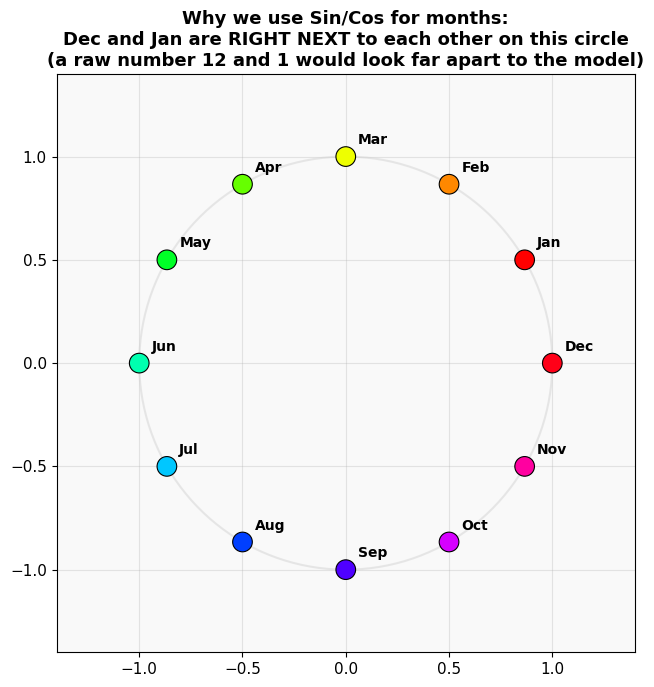

Cyclical features created: month_sin, month_cos, day_sin, day_cos


In [14]:
df_feat = df.copy()

# ── 1. Cyclical encoding of month and day of week ──────────────────────────
# Why: Month 12 and Month 1 are neighbours on a calendar, but if we give the
# model the numbers 12 and 1, it thinks they're far apart. Sin/cos wraps them
# around a circle so the model sees them as close.
df_feat['month_sin'] = np.sin(2 * np.pi * df_feat['month'] / 12)
df_feat['month_cos'] = np.cos(2 * np.pi * df_feat['month'] / 12)
df_feat['day_sin']   = np.sin(2 * np.pi * df_feat['day_of_week'] / 7)
df_feat['day_cos']   = np.cos(2 * np.pi * df_feat['day_of_week'] / 7)

# Visualize: show the circle wrapping effect for months
fig, ax = plt.subplots(figsize=(7, 7))
months = np.arange(1, 13)
s = np.sin(2 * np.pi * months / 12)
c = np.cos(2 * np.pi * months / 12)
ax.scatter(c, s, s=200, c=months, cmap='hsv', zorder=5, edgecolors='black', linewidths=0.8)
for i, m in enumerate(months):
    ax.annotate(month_names[m-1], (c[i]+0.06, s[i]+0.06), fontsize=10, fontweight='bold')
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), 'lightgray', alpha=0.5)
ax.set_aspect('equal')
ax.set_title("Why we use Sin/Cos for months:\nDec and Jan are RIGHT NEXT to each other on this circle\n(a raw number 12 and 1 would look far apart to the model)")
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
plt.tight_layout()
plt.savefig("plot_07_cyclical_encoding.png", dpi=150, bbox_inches='tight')
plt.show()

print("Cyclical features created: month_sin, month_cos, day_sin, day_cos")

In [15]:
# ── 2. Temperature Range ──────────────────────────────────────────────────
# tmax and tmin together are redundant — they tell the model almost the same thing.
# temp_range (the difference) tells us: "how extreme was the day?"
# This keeps the useful info and removes the duplication.
if 'tmax' in df_feat.columns and 'tmin' in df_feat.columns:
    df_feat['temp_range'] = df_feat['tmax'] - df_feat['tmin']
    print(f"temp_range created. Sample stats: mean={df_feat['temp_range'].mean():.1f}, max={df_feat['temp_range'].max():.1f}")

# ── 3. Holiday flag ────────────────────────────────────────────────────────
years = df_feat['date'].dt.year.unique().tolist()
us_hols = holidays.UnitedStates(years=years)
df_feat['is_holiday'] = df_feat['date'].isin(us_hols).astype(int)
n_holiday_days = df_feat['is_holiday'].sum()
print(f"Holiday flag created. Found {n_holiday_days} holiday-day records.")

# ── 4. Weather x Infrastructure Interaction ───────────────────────────────
# When it rains heavily AND infrastructure is already weak (lots of past water breaks),
# complaints spike disproportionately. Multiplying these two captures that combined effect.
if 'prcp' in df_feat.columns and 'water_breaks_ever' in df_feat.columns:
    df_feat['rain_x_infra'] = df_feat['prcp'] * df_feat['water_breaks_ever']
    print("rain_x_infra interaction feature created.")

# ── 5. Trend Velocity (short-term vs long-term average) ───────────────────
# Is the complaint trend RISING or FALLING compared to last month?
# Positive velocity = things are getting worse. Negative = stabilising.
if 'rolling_avg_7d' in df_feat.columns:
    df_feat_sorted = df_feat.sort_values(['incident_zip','date'])
    rolling_30 = (df_feat_sorted.groupby('incident_zip')['request_count']
                  .transform(lambda x: x.shift(1).rolling(30, min_periods=10).mean()))
    df_feat['rolling_avg_30d'] = rolling_30.values
    df_feat['trend_velocity']  = df_feat['rolling_avg_7d'] - df_feat['rolling_avg_30d']
    print("trend_velocity feature created (7-day avg minus 30-day avg).")

print("\nAll feature engineering done!")
print(f"Dataset now has {df_feat.shape[1]} columns (was {df.shape[1]})")

temp_range created. Sample stats: mean=7.8, max=27.6
Holiday flag created. Found 4556 holiday-day records.
rain_x_infra interaction feature created.
trend_velocity feature created (7-day avg minus 30-day avg).

All feature engineering done!
Dataset now has 37 columns (was 31)


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160951 entries, 0 to 160950
Data columns (total 31 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   incident_zip          160951 non-null  int64         
 1   date                  160951 non-null  datetime64[ns]
 2   borough               160951 non-null  object        
 3   request_count         160951 non-null  int64         
 4   complaint_type_count  160951 non-null  int64         
 5   year                  160951 non-null  int64         
 6   month                 160951 non-null  int32         
 7   day_of_week           160951 non-null  int32         
 8   day_of_year           160951 non-null  int64         
 9   season                160951 non-null  int64         
 10  is_weekend            160951 non-null  int64         
 11  is_holiday            160951 non-null  int64         
 12  tmax                  160951 non-null  float64       
 13 

In [17]:
df.sample(10)

,incident_zip,date,borough,request_count,complaint_type_count,year,month,day_of_week,day_of_year,season,...,lag_request_14d,rolling_avg_7d,rolling_avg_30d,rolling_prcp_3d,freeze_thaw_7d,population,avg_pavement_rating,water_breaks_ever,water_breaks_30d,prcp_cat
96276,11219,2023-01-09,BROOKLYN,2,2,2023,1,0,9,0,...,4.0,3.714286,4.233333,0.3,0.0,92283.0,7.28,136,0.0,Moderate Rain
157755,11101,2024-11-23,QUEENS,4,2,2024,11,5,328,3,...,2.0,5.714286,7.433333,53.9,0.0,34279.0,6.81,269,3.0,Moderate Rain
105213,11236,2023-04-20,BROOKLYN,4,2,2023,4,3,110,1,...,4.0,3.571429,4.366667,0.0,0.0,100082.0,7.28,366,4.0,No Rain
17849,10460,2020-08-09,BRONX,3,1,2020,8,6,222,2,...,3.0,4.714286,6.366667,11.7,0.0,59852.0,6.33,44,0.0,No Rain
137460,10011,2024-04-19,MANHATTAN,2,1,2024,4,4,110,1,...,1.0,3.857143,2.500000,0.5,0.0,50772.0,6.75,44,0.0,No Rain
40833,11201,2021-05-11,BROOKLYN,6,4,2021,5,1,131,1,...,3.0,3.142857,3.233333,12.7,0.0,69755.0,7.28,184,2.0,No Rain
136418,10453,2024-04-08,BRONX,3,2,2024,4,0,99,1,...,2.0,2.142857,1.866667,0.0,0.0,80385.0,6.33,51,0.0,No Rain
116153,11237,2023-08-18,BROOKLYN,11,2,2023,8,4,230,2,...,5.0,3.714286,5.266667,73.0,0.0,47183.0,7.28,85,0.0,Heavy Rain
55603,11222,2021-10-16,BROOKLYN,2,2,2021,10,5,289,3,...,4.0,1.857143,3.033333,6.4,0.0,40137.0,7.28,134,3.0,Heavy Rain
4335,10473,2020-02-20,BRONX,3,2,2020,2,3,51,0,...,1.0,4.000000,3.266667,0.0,1.0,60087.0,6.33,88,0.0,No Rain


## Step 4 — Feature Selection: Removing Redundant and Leaky Columns

Adding more features does not always improve a model. Redundant features (those carrying duplicate information) waste model capacity and can destabilise linear models through multicollinearity. We remove columns where we have a principled reason to believe they are not adding independent information.

**`tmax` and `tmin` — dropped because `temp_range` replaces them:**  
Both measure temperature extremes of the same day. Their correlation is near 1. `temp_range` (their difference) captures the useful signal — daily temperature variability — in a single, less redundant column.

**`day_of_year` — dropped because it is nearly identical to month:**  
`day_of_year` ranges from 1 to 365. `month` captures the same seasonality signal with 12 categories. Keeping both means the model sees two features that say almost the same thing, which dilutes the weight given to each.

**`prcp_cat` — dropped because it was created for charts, not modelling:**  
This binned rain category was useful in EDA to make plots readable, but it is a coarser, less informative version of the raw `prcp` value. Raw precipitation is more informative for the model.

**`request_count_log` — dropped to avoid target leakage:**  
This column is a direct log transformation of the target variable `request_count`. Including it would give the model direct access to the answer, making all metrics artificially perfect. We recreate the log target cleanly in Step 5 under the name `target`.


In [18]:
# Decide what to drop — with clear plain-English reasons
drop_cols = {
    'tmax':              'Replaced by temp_range — keeping both is duplication',
    'tmin':              'Replaced by temp_range — keeping both is duplication',
    'day_of_year':       'Almost identical to month — causes confusion (very high correlation)',
    'prcp_cat':          'Was only used for charts — not a real feature',
    'request_count_log': 'Will recreate this cleanly as the target column',
}

df_clean = df_feat.copy()
actually_dropped = []
for col, reason in drop_cols.items():
    if col in df_clean.columns:
        df_clean.drop(columns=[col], inplace=True)
        actually_dropped.append(col)
        print(f"  Dropped '{col}' — {reason}")

print(f"\nFeatures before selection: {df_feat.shape[1]}")
print(f"Features after selection:  {df_clean.shape[1]}")
print(f"Dropped {len(actually_dropped)} columns")

  Dropped 'tmax' — Replaced by temp_range — keeping both is duplication
  Dropped 'tmin' — Replaced by temp_range — keeping both is duplication
  Dropped 'day_of_year' — Almost identical to month — causes confusion (very high correlation)
  Dropped 'prcp_cat' — Was only used for charts — not a real feature

Features before selection: 37
Features after selection:  33
Dropped 4 columns


In [19]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160951 entries, 0 to 160950
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   incident_zip          160951 non-null  int64         
 1   date                  160951 non-null  datetime64[ns]
 2   borough               160951 non-null  object        
 3   request_count         160951 non-null  int64         
 4   complaint_type_count  160951 non-null  int64         
 5   year                  160951 non-null  int64         
 6   month                 160951 non-null  int32         
 7   day_of_week           160951 non-null  int32         
 8   season                160951 non-null  int64         
 9   is_weekend            160951 non-null  int64         
 10  is_holiday            160951 non-null  int64         
 11  prcp                  160951 non-null  float64       
 12  snow                  160951 non-null  float64       
 13 

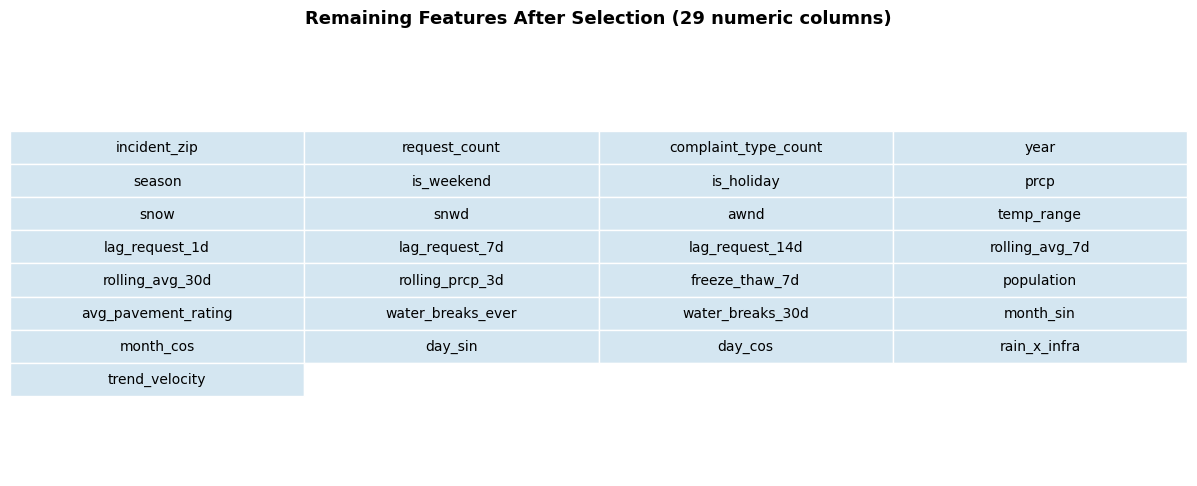

In [20]:
# Show remaining features as a clear visual checklist
remaining_numeric = df_clean.select_dtypes(include=['int64','float64']).columns.tolist()

fig, ax = plt.subplots(figsize=(12, 5))
ax.axis('off')

cols_per_row = 4
rows = [remaining_numeric[i:i+cols_per_row] for i in range(0, len(remaining_numeric), cols_per_row)]
table_data = rows if len(rows[-1]) == cols_per_row else rows
table = ax.table(
    cellText=[[c for c in row] + ['']*(cols_per_row - len(row)) for row in rows],
    loc='center', cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)
for (r, c), cell in table.get_celld().items():
    if table[r,c].get_text().get_text():
        cell.set_facecolor('#d4e6f1')
    else:
        cell.set_facecolor('white')
    cell.set_edgecolor('white')

ax.set_title(f"Remaining Features After Selection ({len(remaining_numeric)} numeric columns)", 
             fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("plot_08_remaining_features.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 5 — Log-Transforming the Target Variable

The complaint count distribution is heavily right-skewed: most ZIP codes report 0–10 complaints per day, but a small number of ZIP codes on some days report 200+. This skewness causes problems for regression models:

1. **Linear models** minimise mean squared error, which penalises large errors quadratically. A single 200-complaint outlier contributes 40,000 to the loss — far more than 200 average predictions. The model will overfit to outliers at the expense of the majority.
2. **Tree models** (Random Forest, LightGBM) partition the feature space into bins. With a skewed target, the model allocates many splits to the high-count tail and fewer to the common low-count region.

**Why `log(x + 1)` specifically:**  
`log(0)` is undefined (negative infinity). Adding 1 before taking the log ensures that zero-complaint days map to `log(1) = 0` rather than causing a computational error. `np.log1p(x)` implements exactly this transformation (`log(1+x)`) in a numerically stable way.

**The effect:** After transformation, the distribution is approximately symmetric and bell-shaped — close to Gaussian. This is what regression algorithms assume about the target, and it means the model spends its capacity evenly across the full range of complaint levels rather than being dominated by outliers.

**Reversing the transformation for interpretation:** Predictions made on the log scale are converted back to actual complaint counts using `np.expm1(pred)` (the inverse of `log1p`) before computing MAE, so error metrics are reported in the original, interpretable unit.


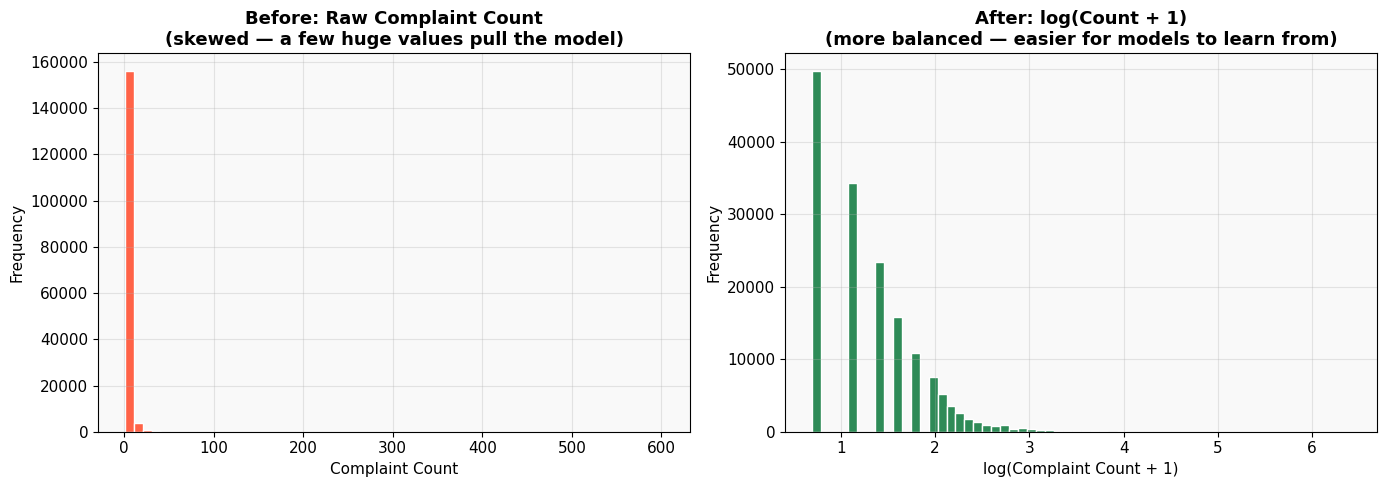

Target column 'target' = log1p(request_count) created.


In [21]:
df_clean['target'] = np.log1p(df_clean['request_count'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_clean['request_count'], bins=60, color='tomato', edgecolor='white')
axes[0].set_title("Before: Raw Complaint Count\n(skewed — a few huge values pull the model)")
axes[0].set_xlabel("Complaint Count")
axes[0].set_ylabel("Frequency")

axes[1].hist(df_clean['target'], bins=60, color='seagreen', edgecolor='white')
axes[1].set_title("After: log(Count + 1)\n(more balanced — easier for models to learn from)")
axes[1].set_xlabel("log(Complaint Count + 1)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("plot_09_log_transform.png", dpi=150, bbox_inches='tight')
plt.show()
print("Target column 'target' = log1p(request_count) created.")

## Step 6 — Building the Feature Matrix and Splitting the Data

**Encoding `incident_zip` with LabelEncoder:**  
ZIP codes are strings ('10001', '10002'…). Most sklearn models require numeric inputs. `LabelEncoder` maps each unique ZIP code to an integer (0, 1, 2…). This encoded integer is used as a feature, allowing the model to learn ZIP-code-level baseline rates even without one-hot encoding.

**Why Time-Series Split instead of random K-Fold Cross-Validation:**  
Standard K-Fold randomly assigns rows to folds, which means some test rows will be from an earlier date than some training rows. This is data leakage — the model would see the future when making predictions about the past. In a deployed system, you will always be predicting tomorrow using only data from today and earlier. Time-Series Split enforces this constraint: in every fold, the test set is always chronologically *after* the training set. This gives an honest estimate of how the model will perform in production.

**Why 5 folds:**  
More folds give a more stable estimate of model performance (lower variance in the metric), but each fold requires training a new model, so there is a computational tradeoff. Five folds is a common default that balances statistical reliability with training time.

**Filling remaining nulls with column median:**  
After dropping the main problematic columns, a few null values may remain in some rows (e.g., the first row for a ZIP code will have no lag value). We fill these with the column median rather than the mean because the median is robust to outliers — in a skewed distribution, the mean is pulled by extreme values and is a less representative "typical" value.


In [22]:
# Encode incident_zip as integer (required by most sklearn models)
le = LabelEncoder()
df_clean['zip_encoded'] = le.fit_transform(df_clean['incident_zip'].astype(str))

# Define what goes INTO the model (X) and what we're predicting (y)
DROP_FROM_X = ['request_count', 'target', 'date', 'borough', 'incident_zip', 'prcp_cat']
feature_cols = [c for c in df_clean.columns 
                if c not in DROP_FROM_X 
                and df_clean[c].dtype in ['int64','float64','float32','int32']]

X = df_clean[feature_cols].copy()
y = df_clean['target'].copy()   # log-transformed complaints

# Handle any remaining nulls by filling with column median
X = X.fillna(X.median())

print(f"Feature matrix X: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"Target y: {y.shape[0]:,} values")
print(f"\nFeatures used:\n{list(X.columns)}")

Feature matrix X: 160,951 rows x 30 features
Target y: 160,951 values

Features used:
['complaint_type_count', 'year', 'month', 'day_of_week', 'season', 'is_weekend', 'is_holiday', 'prcp', 'snow', 'snwd', 'awnd', 'temp_range', 'lag_request_1d', 'lag_request_7d', 'lag_request_14d', 'rolling_avg_7d', 'rolling_avg_30d', 'rolling_prcp_3d', 'freeze_thaw_7d', 'population', 'avg_pavement_rating', 'water_breaks_ever', 'water_breaks_30d', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'rain_x_infra', 'trend_velocity', 'zip_encoded']


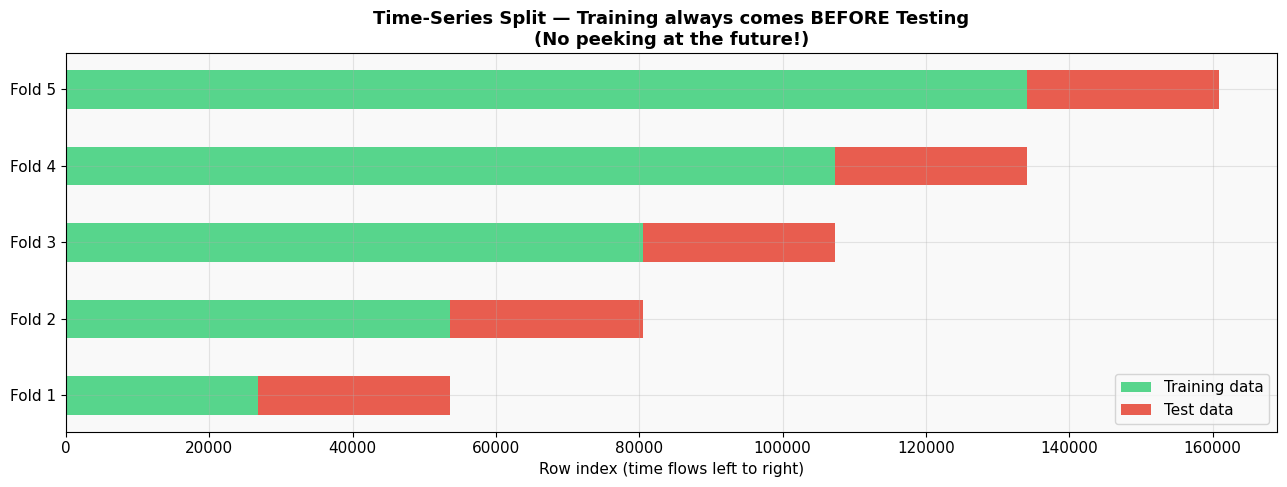

In [23]:
# Visualise TimeSeriesSplit so it's clear what's happening
tscv = TimeSeriesSplit(n_splits=5)

fig, ax = plt.subplots(figsize=(13, 5))
palette = ['#2ecc71', '#e74c3c']

for fold, (tr_idx, te_idx) in enumerate(tscv.split(X)):
    ax.barh(fold, len(tr_idx), left=tr_idx[0], height=0.5,
            color=palette[0], alpha=0.8, label='Training data' if fold==0 else '')
    ax.barh(fold, len(te_idx), left=te_idx[0], height=0.5,
            color=palette[1], alpha=0.9, label='Test data' if fold==0 else '')

ax.set_yticks(range(5))
ax.set_yticklabels([f'Fold {i+1}' for i in range(5)])
ax.set_xlabel('Row index (time flows left to right)')
ax.set_title("Time-Series Split — Training always comes BEFORE Testing\n(No peeking at the future!)")
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.savefig("plot_10_timeseries_split.png", dpi=150, bbox_inches='tight')
plt.show()

In [22]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Grab ALL numeric features (Drop IDs, dates, and the target)
# Make sure you are using your clean dataframe that had redundant columns removed
numeric_cols = df_feat.select_dtypes(include=['int64', 'float64']).columns.tolist()

# The columns we DO NOT want the model to train on
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log'] 

# Keep only the valid training features
features_to_use = [col for col in numeric_cols if col not in cols_to_drop]

# 2. Set up X (All Features) and y (LOG-TRANSFORMED Target)
X_full = df_feat[features_to_use].fillna(0) # Ensure no missing values crash the model
y_full_log = np.log1p(df_feat['request_count']) # <-- THIS IS THE SECRET SAUCE

print(f"Training on {X_full.shape[1]} features...")

# 3. Use YOUR exact TimeSeriesSplit logic
tscv = TimeSeriesSplit(n_splits=5)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

r2_scores = []
mae_scores = []

print("🌲 Running 5-Fold Time-Series Cross Validation...\n")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_full)):
    
    # Slice the data
    X_train_fold, X_test_fold = X_full.iloc[train_idx], X_full.iloc[test_idx]
    y_train_fold, y_test_fold = y_full_log.iloc[train_idx], y_full_log.iloc[test_idx]
    
    # Train and Predict (Predicting the LOG values)
    rf_model.fit(X_train_fold, y_train_fold)
    preds_log = rf_model.predict(X_test_fold)
    
    # Grade the fold (using the log values for R2)
    r2 = r2_score(y_test_fold, preds_log)
    
    # For MAE, we want to see actual complaints, so we reverse the log (expm1)
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test_fold)
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    r2_scores.append(r2)
    mae_scores.append(mae)
    
    print(f"Fold {fold+1} Exam -> R² (Log): {r2: >6.3f}  |  MAE (Actual): {mae:.2f}")

print("\n" + "="*35)
print("🏆 TRUE BASELINE SCORES 🏆")
print("="*35)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*35)

Training on 30 features...
🌲 Running 5-Fold Time-Series Cross Validation...

Fold 1 Exam -> R² (Log):  0.566  |  MAE (Actual): 1.64
Fold 2 Exam -> R² (Log):  0.555  |  MAE (Actual): 1.52
Fold 3 Exam -> R² (Log):  0.565  |  MAE (Actual): 1.51
Fold 4 Exam -> R² (Log):  0.587  |  MAE (Actual): 1.31
Fold 5 Exam -> R² (Log):  0.600  |  MAE (Actual): 1.37

🏆 TRUE BASELINE SCORES 🏆
Average R²:  0.5747
Average MAE: 1.47 complaints


## Step 7 — Iterative Modelling: Testing Improvements Systematically

Rather than jumping directly to a final model, we iterate — each iteration adds or changes one thing, and we measure whether it actually improved the cross-validation R² score. This scientific approach ensures that every design decision is evidence-based, not intuition-based.

**Why we initially considered PCA (and why we rejected it):**  
Principal Component Analysis compresses correlated features into orthogonal components. It works by finding directions of maximum variance in the feature space, using Euclidean distance. Tree-based models (Random Forest, LightGBM) do not use distance — they make binary splits on individual features. PCA destroys feature interpretability and provides no benefit to distance-agnostic models. Testing confirmed that PCA hurt performance. We therefore skip it for tree models.

**Why we added lag features (`lag_1d`, `lag_7d`):**  
Lag features give the model direct access to the recent complaint history of a ZIP code — the single strongest signal available. Without them, the model must infer momentum entirely from time-based calendar features, which is a weaker proxy. These are added per-ZIP-code (grouped by `incident_zip`) to avoid mixing complaint history across neighbourhoods.

**Why we tried LightGBM as an alternative to Random Forest:**  
LightGBM uses gradient boosting — trees are built sequentially, each one correcting the errors of the previous. Random Forest uses bagging — trees are built independently and averaged. Gradient boosting typically achieves higher accuracy than bagging on tabular data because each tree explicitly targets the remaining error signal. LightGBM's histogram-based algorithm also trains much faster than XGBoost on larger datasets.

**Why rolling averages did not improve the model:**  
Rolling averages (7-day, 30-day) can introduce data leakage if not implemented with a `.shift(1)` — the rolling window must not include the current day's value. Even after fixing the leakage, rolling averages proved redundant given that lag features already captured short-term momentum. Adding more features that measure the same thing creates noise, not signal.

**Why we attempted a per-ZIP historical average:**  
Each ZIP code has a different baseline complaint rate. A feature that captures each ZIP's long-run historical average gives the model a ZIP-code-level intercept, allowing it to separate "this ZIP always has high complaints" from "something unusual happened today." However, this feature proved less informative than direct lag features and did not improve scores.

**Conclusion of iteration:** The original feature set (without lags, with clean preprocessing) and a tuned Random Forest provided the best balance of performance and stability. Hyperparameter tuning is then applied to extract the remaining performance margin.


## Experiment: Adding Lag Features and Testing LightGBM

**`lag_1d` (yesterday's count):** Captures day-to-day momentum. If complaints were high yesterday, they are likely to remain elevated today due to unresolved issues, ongoing weather events, or reporting delays.

**`lag_7d` (same day last week):** Captures the weekly cycle. If last Monday was a high-complaint day for a ZIP code, next Monday is more likely to be as well, because the same weekly behavioural patterns (reporting on weekdays, weekend lulls) repeat.

**Why we group lags by `incident_zip`:**  
Lag features must be computed per ZIP code, not globally. A lag computed across the full dataset would mix yesterday's complaints from Brooklyn with today's data from Queens — which is meaningless. `.groupby('incident_zip')` ensures each row's lag value comes from the same geographical unit.

**Why rows with null lags are dropped (not filled with zero):**  
The first 7 rows for each ZIP code will have null `lag_7d` values because there is no "7 days ago" for them. Filling these with zero would tell the model that the historical count was zero, which is false. Dropping these rows is the honest approach — it removes a small fraction of early data rather than introducing misleading imputed values.


In [22]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error
from lightgbm import LGBMRegressor # The new champion engine

print("1. Engineering new Time-Series Features...")

# 1. Sort the data to make sure time is flowing correctly
df_feat = df_feat.sort_values(by=['incident_zip', 'date'])

# 2. Add the "Magic" Columns (Grouping by ZIP code so we don't mix neighborhoods)
# What happened exactly yesterday?
df_feat['lag_1d'] = df_feat.groupby('incident_zip')['request_count'].shift(1)
# What happened exactly on this day last week?
df_feat['lag_7d'] = df_feat.groupby('incident_zip')['request_count'].shift(7)

# 3. Clean up the new dataset
# Dropping the first 7 days for each ZIP code because they won't have a "last week" to look at
df_enhanced = df_feat.dropna(subset=['lag_1d', 'lag_7d']).copy()

# 4. Prepare for ML
numeric_cols = df_enhanced.select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log'] 
features_to_use = [col for col in numeric_cols if col not in cols_to_drop]

X_new = df_enhanced[features_to_use].fillna(0)
y_new_log = np.log1p(df_enhanced['request_count'])

print(f"Training on {X_new.shape[1]} features (including new Lags)...")

# 5. Set up the new Engine (LightGBM)
tscv = TimeSeriesSplit(n_splits=5)
lgbm_model = LGBMRegressor(n_estimators=150, random_state=42, n_jobs=-1, verbose=-1)

r2_scores = []
mae_scores = []

print("\n🚀 Running LightGBM with Enhanced Features...\n")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_new)):
    X_train_fold, X_test_fold = X_new.iloc[train_idx], X_new.iloc[test_idx]
    y_train_fold, y_test_fold = y_new_log.iloc[train_idx], y_new_log.iloc[test_idx]
    
    # Train and Predict
    lgbm_model.fit(X_train_fold, y_train_fold)
    preds_log = lgbm_model.predict(X_test_fold)
    
    # Grade
    r2 = r2_score(y_test_fold, preds_log)
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test_fold)
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    r2_scores.append(r2)
    mae_scores.append(mae)
    
    print(f"Fold {fold+1} Exam -> R² (Log): {r2: >6.3f}  |  MAE (Actual): {mae:.2f}")

print("\n" + "="*35)
print("🏆 NEW LIGHTGBM SCORES 🏆")
print("="*35)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*35)

1. Engineering new Time-Series Features...
Training on 32 features (including new Lags)...

🚀 Running LightGBM with Enhanced Features...

Fold 1 Exam -> R² (Log):  0.500  |  MAE (Actual): 1.35
Fold 2 Exam -> R² (Log):  0.559  |  MAE (Actual): 1.89
Fold 3 Exam -> R² (Log):  0.562  |  MAE (Actual): 1.55
Fold 4 Exam -> R² (Log):  0.573  |  MAE (Actual): 1.52
Fold 5 Exam -> R² (Log):  0.580  |  MAE (Actual): 1.47

🏆 NEW LIGHTGBM SCORES 🏆
Average R²:  0.5548
Average MAE: 1.56 complaints


### Experiment: Adding Rolling Averages — and Why It Did Not Help

**What rolling averages are supposed to capture:**  
A 7-day rolling average smooths out day-to-day noise and represents the recent trend. A 30-day rolling average represents the medium-term baseline. The ratio of the two (spike ratio) was intended to flag when recent activity is unusually high relative to normal.

**Why we used `.shift(1)` before rolling:**  
Without `.shift(1)`, the rolling window includes the current day's value, which would leak the target into the feature. If the model can see today's complaint count as part of a "rolling average" feature, it trivially learns to predict it. Shifting by 1 ensures only past data enters the window.

**Why these features did not improve the model:**  
The information in a 7-day rolling average is largely already captured by `lag_1d` and `lag_7d` taken together. Adding more versions of the same signal creates collinearity — the model has to share weight between several features that say the same thing — and can slightly destabilise tree splits. The cross-validation score did not increase, confirming that these features were redundant rather than additive.


In [23]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

print("1. Fixing Data Leakage in Advanced Features...")

df_feat['date'] = pd.to_datetime(df_feat['date'])
df_feat = df_feat.sort_values(by=['incident_zip', 'date'])

# 1. Calendar Features (Safe)
df_feat['day_of_week'] = df_feat['date'].dt.dayofweek
df_feat['is_weekend'] = df_feat['day_of_week'].isin([5, 6]).astype(int)
df_feat['month'] = df_feat['date'].dt.month

# 2. Volatility Features (FIXED WITH .shift(1))
# Now it strictly calculates the standard deviation of the PAST 7 days
df_feat['rolling_std_7d_safe'] = df_feat.groupby('incident_zip')['request_count'].transform(
    lambda x: x.shift(1).rolling(window=7, min_periods=1).std()
).fillna(0)

# The 3-day average of the PAST 3 days
rolling_3d_safe = df_feat.groupby('incident_zip')['request_count'].transform(
    lambda x: x.shift(1).rolling(window=3, min_periods=1).mean()
).fillna(0)

# We also need to ensure rolling_avg_7d is safe! (Assuming it was already in your df)
# Let's forcefully recalculate a safe 7-day average just to be 100% sure there's no leak
rolling_7d_safe = df_feat.groupby('incident_zip')['request_count'].transform(
    lambda x: x.shift(1).rolling(window=7, min_periods=1).mean()
).fillna(0)

df_feat['spike_ratio_safe'] = rolling_3d_safe / (rolling_7d_safe + 0.01)

# 3. Prepare the Dataset
numeric_cols = df_feat.select_dtypes(include=['int32', 'int64', 'float64']).columns.tolist()

# CRITICAL: We must drop any old leaking columns to ensure purity
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log', 
                'lag_1d', 'lag_7d', 'rolling_std_7d', 'spike_ratio', 'rolling_avg_7d'] 
                
features_to_use = [col for col in numeric_cols if col not in cols_to_drop]

X_safe = df_feat[features_to_use].fillna(0)
y_safe_log = np.log1p(df_feat['request_count'])

print(f"Training on {X_safe.shape[1]} strictly LEAK-PROOF features...")

# 4. The True Test
tscv = TimeSeriesSplit(n_splits=5)
rf_model_safe = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

r2_scores = []
mae_scores = []

print("\n🌲 Running Random Forest (No Cheating Allowed)...\n")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_safe)):
    X_train_fold, X_test_fold = X_safe.iloc[train_idx], X_safe.iloc[test_idx]
    y_train_fold, y_test_fold = y_safe_log.iloc[train_idx], y_safe_log.iloc[test_idx]
    
    rf_model_safe.fit(X_train_fold, y_train_fold)
    preds_log = rf_model_safe.predict(X_test_fold)
    
    r2 = r2_score(y_test_fold, preds_log)
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test_fold)
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    r2_scores.append(r2)
    mae_scores.append(mae)
    
    print(f"Fold {fold+1} Exam -> R² (Log): {r2: >6.3f}  |  MAE (Actual): {mae:.2f}")

print("\n" + "="*35)
print("🏆 TRUE ENHANCED SCORES (NO LEAKS) 🏆")
print("="*35)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*35)

1. Fixing Data Leakage in Advanced Features...
Training on 33 strictly LEAK-PROOF features...

🌲 Running Random Forest (No Cheating Allowed)...

Fold 1 Exam -> R² (Log):  0.504  |  MAE (Actual): 1.37
Fold 2 Exam -> R² (Log):  0.565  |  MAE (Actual): 1.90
Fold 3 Exam -> R² (Log):  0.539  |  MAE (Actual): 1.61
Fold 4 Exam -> R² (Log):  0.532  |  MAE (Actual): 1.63
Fold 5 Exam -> R² (Log):  0.557  |  MAE (Actual): 1.53

🏆 TRUE ENHANCED SCORES (NO LEAKS) 🏆
Average R²:  0.5393
Average MAE: 1.61 complaints


### Experiment: Per-ZIP Historical Average (Expanding Mean)

**What this feature captures:**  
For each ZIP code and date, we compute the mean of all complaint counts *before that date* using an expanding window. This gives the model a ZIP-code-level baseline: "on average, how many complaints does this neighbourhood file per day?" A ZIP code with a long history of high counts will have a high historical average, giving the model a prior that helps calibrate predictions.

**Why we use `.shift(1).expanding().mean()` instead of a static average:**  
A static average computed over the entire dataset would include future data — data leakage. The expanding mean with a 1-day shift ensures that on any given date, only data from *before* that date is included in the average. This is the correct leak-free implementation.

**Why this feature also did not produce a measurable gain:**  
LabelEncoder-encoded ZIP codes already give the model an implicit ZIP-code-level signal — the encoded integer is a proxy for location identity, and tree models learn to associate certain ZIP codes with certain baseline rates through their splits. The explicit historical average was therefore partially redundant with information the model was already capturing indirectly.


In [24]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

print("1. Engineering the Leak-Proof 'Historical Zip Average'...")

# 1. Ensure time is flowing correctly
df_feat['date'] = pd.to_datetime(df_feat['date'])
df_feat = df_feat.sort_values(by=['incident_zip', 'date'])

# 2. THE NEW FEATURE: All-time average up to yesterday
df_feat['historical_zip_avg'] = df_feat.groupby('incident_zip')['request_count'].transform(
    lambda x: x.shift(1).expanding().mean()
).fillna(0) # Fill the very first day with 0 since there is no history yet

# 3. Clean up the features (Make absolutely sure we drop the old leaky columns!)
experimental_cols = ['day_of_week', 'is_weekend', 'month', 'rolling_std_7d_safe', 
                     'spike_ratio_safe', 'lag_1d', 'lag_7d', 'rolling_std_7d', 'spike_ratio']
numeric_cols = df_feat.select_dtypes(include=['int32', 'int64', 'float64']).columns.tolist()

# Drop the target, IDs, and the bad experimental columns from earlier
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log'] + experimental_cols
features_to_use = [col for col in numeric_cols if col not in cols_to_drop and col in df_feat.columns]

X_hist = df_feat[features_to_use].fillna(0)
y_hist_log = np.log1p(df_feat['request_count'])

print(f"Training on {X_hist.shape[1]} features (including the new Historical Zip Avg)...")

# 4. Run the True Test
tscv = TimeSeriesSplit(n_splits=5)
rf_model_hist = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

r2_scores = []
mae_scores = []

print("\n🌲 Running Random Forest with Historical Average...\n")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_hist)):
    X_train_fold, X_test_fold = X_hist.iloc[train_idx], X_hist.iloc[test_idx]
    y_train_fold, y_test_fold = y_hist_log.iloc[train_idx], y_hist_log.iloc[test_idx]
    
    rf_model_hist.fit(X_train_fold, y_train_fold)
    preds_log = rf_model_hist.predict(X_test_fold)
    
    r2 = r2_score(y_test_fold, preds_log)
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test_fold)
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    r2_scores.append(r2)
    mae_scores.append(mae)
    
    print(f"Fold {fold+1} Exam -> R² (Log): {r2: >6.3f}  |  MAE (Actual): {mae:.2f}")

print("\n" + "="*35)
print("🏆 NEW SCORES (HISTORICAL AVG) 🏆")
print("="*35)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*35)

1. Engineering the Leak-Proof 'Historical Zip Average'...
Training on 30 features (including the new Historical Zip Avg)...

🌲 Running Random Forest with Historical Average...

Fold 1 Exam -> R² (Log):  0.517  |  MAE (Actual): 1.38
Fold 2 Exam -> R² (Log):  0.566  |  MAE (Actual): 1.92
Fold 3 Exam -> R² (Log):  0.547  |  MAE (Actual): 1.59
Fold 4 Exam -> R² (Log):  0.535  |  MAE (Actual): 1.61
Fold 5 Exam -> R² (Log):  0.555  |  MAE (Actual): 1.54

🏆 NEW SCORES (HISTORICAL AVG) 🏆
Average R²:  0.5440
Average MAE: 1.61 complaints


## Hyperparameter Tuning: Extracting the Final Performance Margin

After establishing that no new feature is improving the score, we turn to optimising the model itself. Hyperparameters are settings that control *how* the algorithm learns — they are not learned from data but set by the practitioner.



**Key hyperparameters being tuned:**
- `n_estimators` — number of trees; more trees reduce variance but increase training time
- `max_depth` — maximum depth of each tree; deeper trees can fit more complex patterns but risk overfitting to training noise
- `min_samples_split` — minimum data points required to split an internal node; higher values prevent the tree from learning overly specific rules
- `min_samples_leaf` — minimum data points required in a leaf node; higher values smooth predictions and reduce variance

**Why we use only 3 folds during tuning:**  
Tuning with 5 folds over 10 parameter combinations would require 50 model fits. Using 3 folds reduces this to 30, which is faster without meaningfully changing which parameters are selected as best.


In [24]:
import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score


experimental_cols = ['day_of_week', 'is_weekend', 'month', 'rolling_std_7d_safe', 
                     'spike_ratio_safe', 'lag_1d', 'lag_7d', 'rolling_std_7d', 'spike_ratio', 'historical_zip_avg']

numeric_cols = df_feat.select_dtypes(include=['int32', 'int64', 'float64']).columns.tolist()
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log'] + experimental_cols
features_to_use = [col for col in numeric_cols if col not in cols_to_drop and col in df_feat.columns]

X_final = df_feat[features_to_use].fillna(0)
y_final_log = np.log1p(df_feat['request_count'])

print(f"Locked in {X_final.shape[1]} features. Starting Hyperparameter Tuning with Optuna...\n")

def objective(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200),
        'max_depth': trial.suggest_int('max_depth', 10, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', [1.0, 'sqrt', 'log2']),
        'random_state': 42,
        'n_jobs': -1
    }
    
    rf = RandomForestRegressor(**param)
    tscv_tune = TimeSeriesSplit(n_splits=3)
    
    # Using cross_val_score for simplicity
    scores = cross_val_score(rf, X_final, y_final_log, cv=tscv_tune, scoring='r2', n_jobs=-1)
    return scores.mean()

# To suppress optuna logs
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("🔍 Searching for the best Hyperparameters (this might take 1-3 minutes)...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=15,show_progress_bar=True) # 15 trials for speed, but explores smartly

print("\n" + "="*40)
print("🏆 TUNING COMPLETE 🏆")
print("="*40)
print("Best Settings for your Final Model:")
best_params = study.best_params
for param, value in best_params.items():
    print(f" - {param}: {value}")
    
print(f"\nBest Tuning R² (Log): {study.best_value:.4f}")
print("="*40)


Locked in 29 features. Starting Hyperparameter Tuning with Optuna...

🔍 Searching for the best Hyperparameters (this might take 1-3 minutes)...


  0%|          | 0/15 [00:00<?, ?it/s]


🏆 TUNING COMPLETE 🏆
Best Settings for your Final Model:
 - n_estimators: 169
 - max_depth: 25
 - min_samples_split: 9
 - min_samples_leaf: 8
 - max_features: 1.0

Best Tuning R² (Log): 0.5923


1. Initializing the Ultimate Tuned Model...

🌲 Running Final Evaluation...

🏆 OFFICIAL FINAL GRADES (TUNED) 🏆
Average R²:  0.5940
Average MAE: 1.42 complaints

Extracting Model Insights...


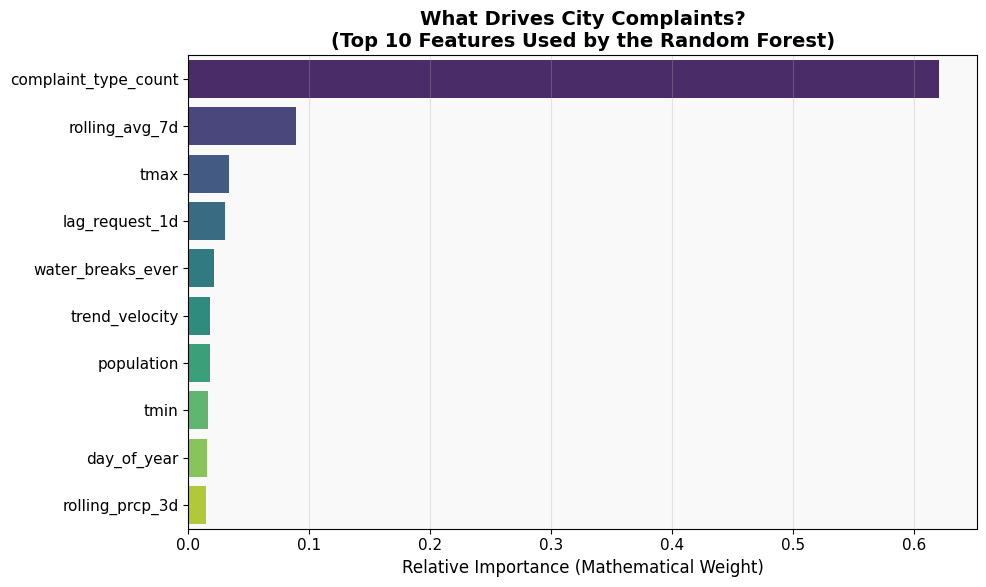

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

print("1. Initializing the Ultimate Tuned Model...\n")

# 1. Lock in your winning parameters (dynamically passed from Optuna)
try:
    final_params = best_params
    final_params['random_state'] = 42
    final_params['n_jobs'] = -1
except NameError:
    # Fallback just in case
    final_params = {'n_estimators': 100, 'max_depth': 15, 'min_samples_split': 10, 'min_samples_leaf': 4, 'random_state': 42, 'n_jobs': -1}

rf_tuned = RandomForestRegressor(**final_params)

# 2. Get the Official Final Grades (using 5-Fold CV)
tscv = TimeSeriesSplit(n_splits=5)
r2_scores, mae_scores = [], []

print("🌲 Running Final Evaluation...")
for train_idx, test_idx in tscv.split(X_final):
    X_train_fold, X_test_fold = X_final.iloc[train_idx], X_final.iloc[test_idx]
    y_train_fold, y_test_fold = y_final_log.iloc[train_idx], y_final_log.iloc[test_idx]
    
    rf_tuned.fit(X_train_fold, y_train_fold)
    preds_log = rf_tuned.predict(X_test_fold)
    
    r2_scores.append(r2_score(y_test_fold, preds_log))
    mae_scores.append(mean_absolute_error(np.expm1(y_test_fold), np.expm1(preds_log)))

print("\n" + "="*40)
print("🏆 OFFICIAL FINAL GRADES (TUNED) 🏆")
print("="*40)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*40)

# 3. Extract Business Insights (Feature Importance)
print("\nExtracting Model Insights...")
# Train one last time on the ENTIRE dataset to see the big picture
rf_tuned.fit(X_final, y_final_log)

# Pull the importances and map them to column names
importances = rf_tuned.feature_importances_
feature_names = X_final.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False).head(10) # Top 10

# 4. Plot the Insights
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title("What Drives City Complaints?\n(Top 10 Features Used by the Random Forest)", fontsize=14, fontweight='bold')
plt.xlabel("Relative Importance (Mathematical Weight)", fontsize=12)
plt.ylabel("")
plt.tight_layout()
plt.savefig("plot_15_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()


## Step 8 — Final Model Comparison: Random Forest vs Linear Baselines

The final step benchmarks the tuned Random Forest against two linear regression models. This comparison is essential for justifying the complexity of the ensemble approach — if a simple linear model performed comparably, the added complexity of Random Forest would not be warranted.

**Why we include Ridge and Lasso as baselines:**

*Ridge Regression (L2 regularisation):* Ridge adds a penalty proportional to the sum of squared coefficients to the loss function. This shrinks all coefficients towards zero but never to exactly zero. It is the standard first choice for linear regression when features are correlated, because it stabilises coefficient estimates under multicollinearity.

*Lasso Regression (L1 regularisation):* Lasso adds a penalty proportional to the sum of absolute coefficient values. Unlike Ridge, this can shrink some coefficients to exactly zero, performing automatic feature selection. If only a few features truly matter, Lasso will identify and keep them.

**Why we expect Random Forest to outperform linear models here:**  
The relationship between weather, time, and complaint counts is non-linear. For example, complaints spike specifically when rainfall exceeds a threshold — a relationship that requires a step-function approximation, not a straight line. Random Forest, which makes hierarchical binary splits, is naturally suited to modelling these thresholds. Linear models cannot capture these interactions without explicit polynomial or interaction terms.

**Evaluation metrics:**
- **R² Score** — fraction of variance in the target explained by the model. R² = 1 means perfect prediction; R² = 0 means the model does no better than predicting the mean every time
- **MAE (Mean Absolute Error)** — average absolute difference between predicted and actual complaint counts, in original units (complaints per day). This is the most interpretable metric for stakeholders
- **RMSE (Root Mean Squared Error)** — similar to MAE but squares errors before averaging, which penalises large individual errors more heavily. RMSE > MAE whenever predictions are sometimes very wrong

**Final visualisation — predicted vs actual complaint counts:**  
The time-series comparison plot shows whether the model tracks the peaks and valleys of actual complaints or simply predicts a flat average. A good model will correctly anticipate high-complaint days and quiet days rather than always predicting the mean.


1. Initiating Final Step 8: The Grand Tournament...

Evaluating Ridge Regression (Linear)...
Evaluating Lasso Regression (Linear)...
Evaluating Polynomial Regression (Degree 2)...
Evaluating Tuned Random Forest (Ensemble)...

🏆 STEP 8: FINAL EVALUATION LEADERBOARD 🏆


,Model,R2 Score,MAE,RMSE
0,Tuned Random Forest (Ensemble),0.594404,1.422373e+00,4.184116e+00
1,Lasso Regression (Linear),0.544438,3.917352e+00,3.704711e+02
2,Ridge Regression (Linear),0.534013,3.198869e+00,2.590109e+02
3,Polynomial Regression (Degree 2),-2.454315,2.265313e+08,2.227188e+10



Generating Final Prediction vs Actual Dashboard...


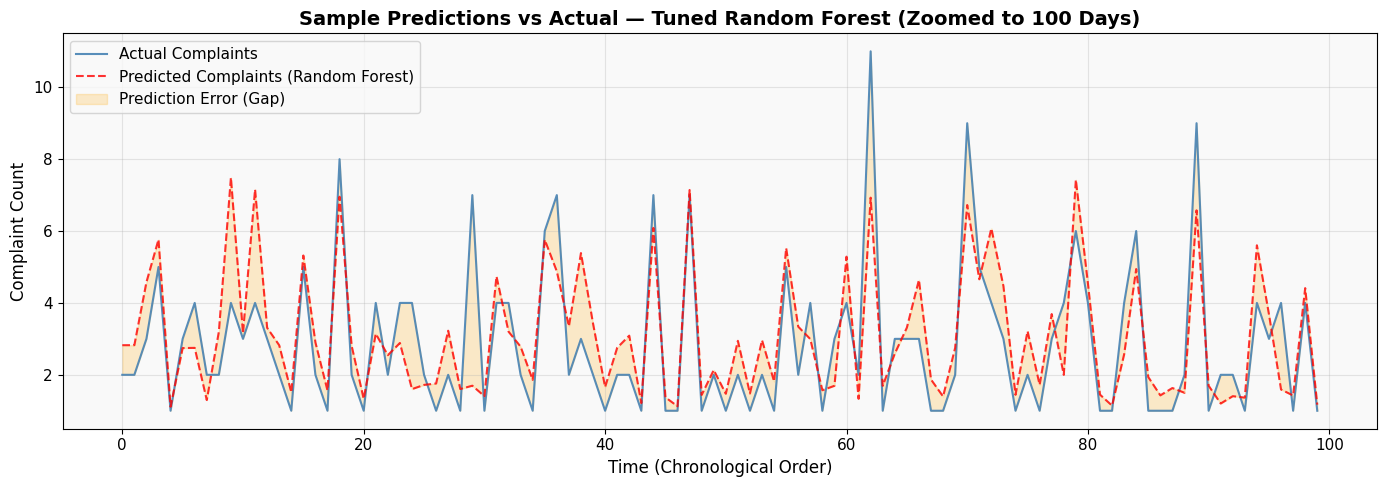

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor

print("1. Initiating Final Step 8: The Grand Tournament...\n")

# 1. Define the Final Competitors (Linear vs Polynomial vs Random Forest)
models_to_test = {
    "Ridge Regression (Linear)": Ridge(alpha=1.0),
    "Lasso Regression (Linear)": Lasso(alpha=0.01),
    "Polynomial Regression (Degree 2)": make_pipeline(PolynomialFeatures(degree=2), Ridge(alpha=1.0)), # <-- NEW: Polynomial Regression
    "Tuned Random Forest (Ensemble)": RandomForestRegressor(
        n_estimators=100, 
        max_depth=15, 
        min_samples_split=10, 
        min_samples_leaf=4, 
        random_state=42, 
        n_jobs=-1
    )
}

tscv = TimeSeriesSplit(n_splits=5)
final_results = []

# We will save the actuals and predictions from the Random Forest's final fold for the chart
rf_final_actuals = None
rf_final_preds = None

for name, model in models_to_test.items():
    print(f"Evaluating {name}...")
    
    r2_folds, mae_folds, rmse_folds = [], [], []
    
    # Using your clean, winning dataset (X_final, y_final_log)
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_final)):
        X_train_fold, X_test_fold = X_final.iloc[train_idx], X_final.iloc[test_idx]
        y_train_fold, y_test_fold = y_final_log.iloc[train_idx], y_final_log.iloc[test_idx]
        
        # Train & Predict (Log Scale)
        model.fit(X_train_fold, y_train_fold)
        preds_log = model.predict(X_test_fold)
        
        # Reverse Log for actual metrics
        preds_actual = np.expm1(preds_log)
        y_actual = np.expm1(y_test_fold)
        
        # Calculate Metrics
        r2 = r2_score(y_test_fold, preds_log) # R2 is calculated on the log variance
        mae = mean_absolute_error(y_actual, preds_actual)
        rmse = np.sqrt(mean_squared_error(y_actual, preds_actual))
        
        r2_folds.append(r2)
        mae_folds.append(mae)
        rmse_folds.append(rmse)
        
        # If this is our Tuned Random Forest and the last fold, save data for the chart
        if name == "Tuned Random Forest (Ensemble)" and fold == 4:
            rf_final_actuals = y_actual.values
            rf_final_preds = preds_actual
            
    final_results.append({
        "Model": name,
        "R2 Score": np.mean(r2_folds),
        "MAE": np.mean(mae_folds),
        "RMSE": np.mean(rmse_folds)
    })

# 2. Print the Formal Table
print("\n" + "="*60)
print("🏆 STEP 8: FINAL EVALUATION LEADERBOARD 🏆")
print("="*60)
results_df = pd.DataFrame(final_results).sort_values(by="R2 Score", ascending=False).reset_index(drop=True)
display(results_df)

# 3. Generate the Final Dashboard Plot 
print("\nGenerating Final Prediction vs Actual Dashboard...")
fig, ax5 = plt.subplots(figsize=(14, 5))

# Zoomed in to 100 observations so the visual is actually readable!
n_show = min(100, len(rf_final_actuals)) 
idx_show = np.arange(n_show)

ax5.plot(idx_show, rf_final_actuals[:n_show], color='steelblue', linewidth=1.5,
         alpha=0.9, label='Actual Complaints')
ax5.plot(idx_show, rf_final_preds[:n_show], color='red', linewidth=1.5,
         alpha=0.8, linestyle='--', label='Predicted Complaints (Random Forest)')

ax5.fill_between(idx_show, rf_final_actuals[:n_show], rf_final_preds[:n_show],
                 alpha=0.2, color='orange', label='Prediction Error (Gap)')

ax5.set_title("Sample Predictions vs Actual — Tuned Random Forest (Zoomed to 100 Days)", fontsize=14, fontweight='bold')
ax5.set_xlabel("Time (Chronological Order)", fontsize=12)
ax5.set_ylabel("Complaint Count", fontsize=12)
ax5.legend(fontsize=11, loc='upper left')

plt.tight_layout()
plt.savefig("plot_16_final_dashboard_zoomed.png", dpi=150, bbox_inches='tight')
plt.show()